# House Prices Prediction

Machine learning model to predict house prices (Kaggle: *House Prices - Advanced Regression Techniques*).

**Run the cells from top to bottom.**

## Setup: import libraries

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
pd.set_option("display.max_columns", 100)

# Task 1: Data Exploration & Preprocessing

## Task 1.1: Load the dataset and display basic statistics

In [2]:
# Use a local train.csv if it exists, otherwise download it with kagglehub
if os.path.exists("train.csv"):
    train_path = "train.csv"
else:
    import kagglehub
    path = kagglehub.competition_download("house-prices-advanced-regression-techniques")
    print("Path to competition files:", path)
    train_path = os.path.join(path, "train.csv")
    

df = pd.read_csv(train_path)
df = df.drop(columns=["Id"])          # Id is just a row number, not a feature

print("Shape:", df.shape)               # expect (1460, 80)
df.head()

Shape: (1460, 80)


,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 80 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   MSSubClass     1460 non-null   int64  
 1   MSZoning       1460 non-null   str    
 2   LotFrontage    1201 non-null   float64
 3   LotArea        1460 non-null   int64  
 4   Street         1460 non-null   str    
 5   Alley          91 non-null     str    
 6   LotShape       1460 non-null   str    
 7   LandContour    1460 non-null   str    
 8   Utilities      1460 non-null   str    
 9   LotConfig      1460 non-null   str    
 10  LandSlope      1460 non-null   str    
 11  Neighborhood   1460 non-null   str    
 12  Condition1     1460 non-null   str    
 13  Condition2     1460 non-null   str    
 14  BldgType       1460 non-null   str    
 15  HouseStyle     1460 non-null   str    
 16  OverallQual    1460 non-null   int64  
 17  OverallCond    1460 non-null   int64  
 18  YearBuilt      1460

In [4]:
# Basic statistics: numeric columns
df.describe().T

,count,mean,std,min,25%,50%,75%,max
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0
BsmtFinSF2,1460.0,46.549315,161.319273,0.0,0.00,0.0,0.00,1474.0


In [5]:
# Basic statistics: categorical columns
df.describe(include="object").T

,count,unique,top,freq
MSZoning,1460,5,RL,1151
Street,1460,2,Pave,1454
Alley,91,2,Grvl,50
LotShape,1460,4,Reg,925
LandContour,1460,4,Lvl,1311
Utilities,1460,2,AllPub,1459
LotConfig,1460,5,Inside,1052
LandSlope,1460,3,Gtl,1382
Neighborhood,1460,25,NAmes,225
Condition1,1460,9,Norm,1260


### Interpretation: Task 1.1 (basic statistics)

**What the data looks like.** The training set has **1,460 houses** and **80 columns** (after dropping `Id`): 37 numeric columns (including the target `SalePrice`) and 43 text/category columns. Each row is one house sold in Ames, Iowa, and each column describes it (size, quality, age, neighborhood, garage, basement, etc.).

**Numeric statistics (`describe`)**
- `SalePrice` averages about **$181k** with a median of **$163k**. The mean is higher than the median, so a few very expensive houses (max $755k) pull the average up. The distribution is **right-skewed**, which is why we use a log transform later.
- `OverallQual` (quality from 1 to 10) averages 6.1, and a typical house has about 1,500 sq ft of living area (`GrLivArea`).
- `LotArea` has a large standard deviation (~10k) compared with its mean (~10.5k), meaning a few huge lots stretch the scale. The columns also have very different scales (years around 1970, areas in the thousands, quality from 1 to 10). This is why scaling is needed later.

**Categorical statistics.** `describe(include="object")` shows the number of unique values and the most common one. For example, `Neighborhood` has 25 values (`NAmes` is the most common with 225 houses), and 1,151 of the 1,460 houses are zoned `RL` (residential low density). Some columns are almost constant: `Street` is `Pave` for 1,454 houses and `Utilities` is `AllPub` for 1,459. These columns carry almost no information for the model.

## Task 1.2: Handle missing values appropriately

              Missing  Percent
PoolQC           1453    99.52
MiscFeature      1406    96.30
Alley            1369    93.77
Fence            1179    80.75
MasVnrType        872    59.73
FireplaceQu       690    47.26
LotFrontage       259    17.74
GarageType         81     5.55
GarageYrBlt        81     5.55
GarageFinish       81     5.55
GarageQual         81     5.55
GarageCond         81     5.55
BsmtExposure       38     2.60
BsmtFinType2       38     2.60
BsmtQual           37     2.53
BsmtCond           37     2.53
BsmtFinType1       37     2.53
MasVnrArea          8     0.55
Electrical          1     0.07


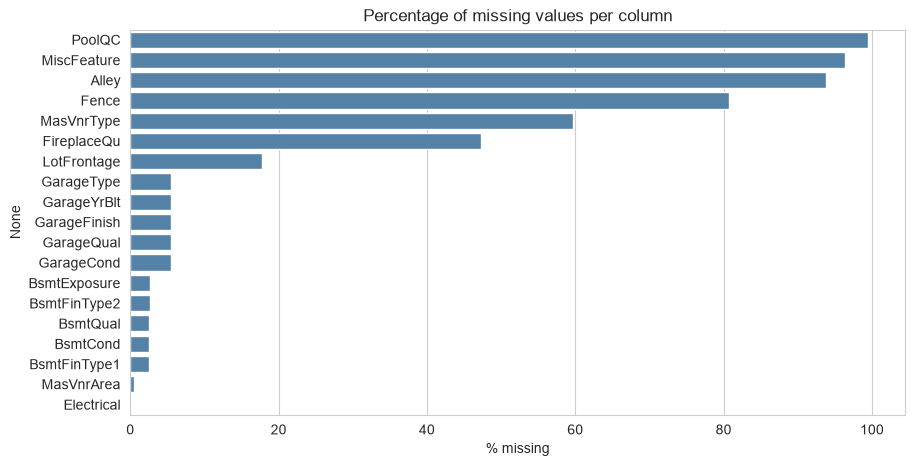

In [6]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing_df = pd.DataFrame({"Missing": missing, "Percent": (missing / len(df) * 100).round(2)})
print(missing_df)

plt.figure(figsize=(10, 5))
sns.barplot(x=missing_df["Percent"], y=missing_df.index, color="steelblue")
plt.title("Percentage of missing values per column")
plt.xlabel("% missing")
plt.show()

In [7]:
# 1) For these columns, NaN means "the house does not have this feature" -> fill with "None"
none_cols = ["PoolQC", "MiscFeature", "Alley", "Fence", "FireplaceQu",
             "GarageType", "GarageFinish", "GarageQual", "GarageCond",
             "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
             "MasVnrType"]
for c in none_cols:
    df[c] = df[c].fillna("None")

# 2) Numeric columns where NaN means "none" -> fill with 0
for c in ["GarageYrBlt", "MasVnrArea"]:
    df[c] = df[c].fillna(0)

# 3) LotFrontage: use the median of houses in the same neighborhood
df["LotFrontage"] = df.groupby("Neighborhood")["LotFrontage"].transform(lambda s: s.fillna(s.median()))

# 4) Anything left: median for numeric columns, mode for categorical columns
num_cols = df.select_dtypes(include="number").columns
cat_cols = df.select_dtypes(exclude="number").columns
df[num_cols] = df[num_cols].fillna(df[num_cols].median())
for c in cat_cols:
    df[c] = df[c].fillna(df[c].mode()[0])

print("Missing values left:", df.isnull().sum().sum())

Missing values left: 0


### Interpretation: Task 1.2 (missing values)

**What was missing.** 19 columns have missing values. The biggest ones are `PoolQC` (99.5%), `MiscFeature` (96.3%), `Alley` (93.8%), `Fence` (80.8%), `MasVnrType` (59.7%) and `FireplaceQu` (47.3%).

**Why that is not really a problem.** In this dataset a missing value usually does **not** mean "data lost". It means **the house does not have that feature**: no pool, no alley, no fence, no fireplace, no garage, no basement. So we did not delete these columns or fill them with an average. We filled them with the category `"None"`, because "no pool" is real information that affects the price.

**How each group was handled**
- **Missing = no feature (text columns):** filled with `"None"` (pool, fence, fireplace, garage, basement columns, etc.).
- **Missing = no feature (numeric columns):** `GarageYrBlt` and `MasVnrArea` filled with `0`.
- **`LotFrontage` (17.7% missing):** this is a real gap, so we filled it with the **median of the same neighborhood**, since houses in one neighborhood have similar street frontage. This is more accurate than one global median.
- **The rest (one or two rows):** the median for numeric columns and the most frequent value for categorical columns.

The final check shows **0 missing values left**, so the models will not crash on NaN values and no rows were thrown away.

## Task 1.3: Perform exploratory data analysis (EDA) with visualizations

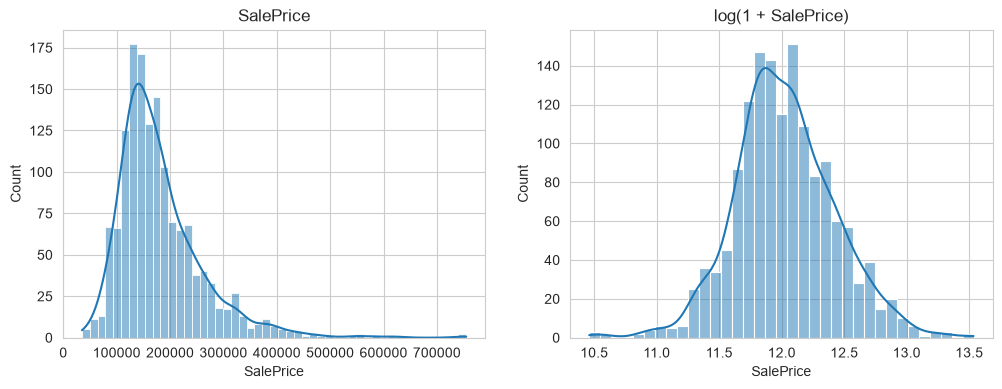

Skewness of SalePrice: 1.88
Skewness of log(SalePrice): 0.12


In [8]:
# Target variable: SalePrice (right-skewed, so we will use log(1 + price) later)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["SalePrice"], kde=True, ax=axes[0])
axes[0].set_title("SalePrice")
sns.histplot(np.log1p(df["SalePrice"]), kde=True, ax=axes[1])
axes[1].set_title("log(1 + SalePrice)")
plt.show()

print("Skewness of SalePrice:", round(df["SalePrice"].skew(), 2))
print("Skewness of log(SalePrice):", round(np.log1p(df["SalePrice"]).skew(), 2))

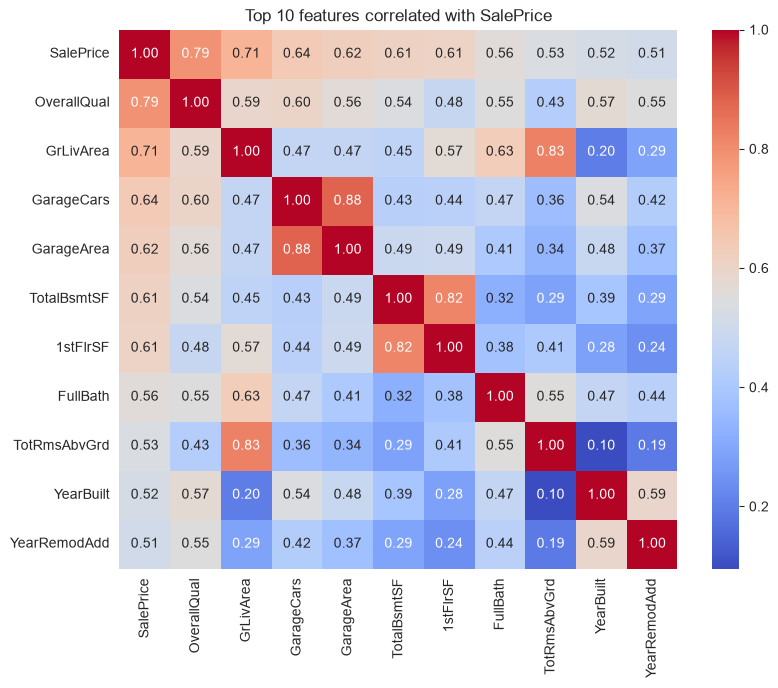

In [9]:
# Correlation heatmap: top 10 numeric features most correlated with SalePrice
corr = df.select_dtypes(include="number").corr()
top_features = corr["SalePrice"].abs().sort_values(ascending=False).head(11).index

plt.figure(figsize=(9, 7))
sns.heatmap(df[top_features].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Top 10 features correlated with SalePrice")
plt.show()

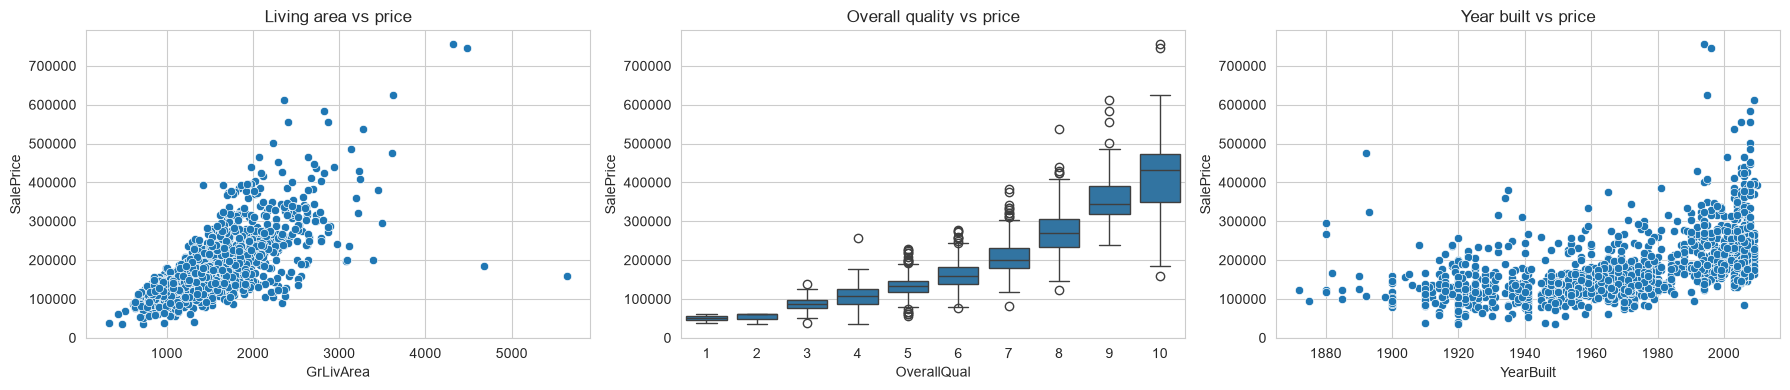

In [10]:
# Relationship between key features and price
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
sns.scatterplot(x="GrLivArea", y="SalePrice", data=df, ax=axes[0])
axes[0].set_title("Living area vs price")
sns.boxplot(x="OverallQual", y="SalePrice", data=df, ax=axes[1])
axes[1].set_title("Overall quality vs price")
sns.scatterplot(x="YearBuilt", y="SalePrice", data=df, ax=axes[2])
axes[2].set_title("Year built vs price")
plt.tight_layout()
plt.show()

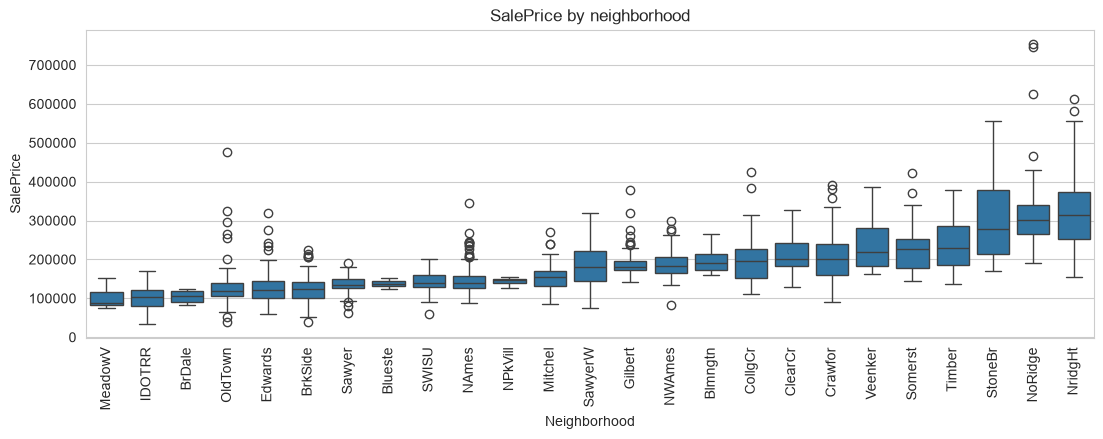

In [11]:
# Price by neighborhood
order = df.groupby("Neighborhood")["SalePrice"].median().sort_values().index
plt.figure(figsize=(13, 4))
sns.boxplot(x="Neighborhood", y="SalePrice", data=df, order=order)
plt.xticks(rotation=90)
plt.title("SalePrice by neighborhood")
plt.show()

In [12]:
# Two very large houses sold for very low prices (clear outliers, see first scatter plot). Remove them.
before = len(df)
df = df[~((df["GrLivArea"] > 4000) & (df["SalePrice"] < 300000))].reset_index(drop=True)
print("Rows removed:", before - len(df))

Rows removed: 2


### Interpretation: Task 1.3 (exploratory data analysis)

**Target variable.** `SalePrice` has a skewness of **1.88** (strongly right-skewed: many cheap and medium houses, a long tail of expensive ones). After the `log(1 + price)` transformation the skewness drops to **0.12**, which is almost a symmetric bell shape. Linear models work best with roughly normal targets, and the log also makes the errors relative (a $20k mistake matters more on a $100k house than on a $500k one). This is why the models predict log price and the result is converted back to dollars with `expm1`.

**Correlation heatmap.** The features most related to price are overall quality (`OverallQual`), living area (`GrLivArea`), basement area (`TotalBsmtSF`) and garage size (`GarageCars` / `GarageArea`). The heatmap also shows that some features are strongly correlated **with each other** (for example `GarageCars` with `GarageArea`, and `TotalBsmtSF` with `1stFlrSF`). That is called multicollinearity, and it matters later for Linear Regression, Ridge and Lasso.

**Key relationships**
- **Living area vs price:** price rises with size in a roughly straight line (so a linear model is reasonable), and the spread gets wider for bigger houses. The two points at the far right (over 4,500 sq ft, cheap) are the outliers described below.
- **Quality vs price:** the median price climbs steadily with each quality level, and the jumps get bigger at the top (levels 8 to 10, up to a median of about $430k at level 10), with a wider spread too.
- **Year built vs price:** prices stay fairly flat for houses built before about 1950 and then rise, especially for houses built after about 1980. Recent houses also have the widest range of prices.

**Neighborhood.** Location clearly matters. Median prices go from about **$88k in MeadowV** (and about $103k in IDOTRR and $106k in BrDale) up to about **$278k–$315k in StoneBr, NoRidge and NridgHt**. The expensive neighborhoods also have the widest price ranges, so `Neighborhood` should be kept as a feature.

**Outliers.** The first scatter plot shows two houses with a very large living area (over 4,000 sq ft) that sold for under $300k. They are unusual sales that do not follow the pattern and would pull a regression line down, so we **removed 2 rows** (1,460 to 1,458).

## Task 1.4: Convert categorical variables into numerical representations

In [13]:
# MSSubClass is a category code stored as a number, so treat it as a category
df["MSSubClass"] = df["MSSubClass"].astype(str)

# One-hot encoding
df_encoded = pd.get_dummies(df, drop_first=True, dtype=int)

# Remove very rare dummy columns (fewer than 10 houses): they add noise and can break Linear Regression
numeric_cols = df.select_dtypes(include="number").columns
dummy_cols = [c for c in df_encoded.columns if c not in numeric_cols]
rare = [c for c in dummy_cols if df_encoded[c].sum() < 10]
df_encoded = df_encoded.drop(columns=rare)

print("Shape before encoding:", df.shape)
print("Shape after encoding :", df_encoded.shape)
print("Dummy columns removed as too rare:", len(rare))

Shape before encoding: (1458, 80)
Shape after encoding : (1458, 212)
Dummy columns removed as too rare: 60


### Interpretation: Task 1.4 (encoding categorical variables)

**Why it is needed.** Machine learning models can only work with numbers, so text columns such as `Neighborhood = "CollgCr"` must be converted.

**What we did**
- `MSSubClass` is a building-type *code* (20, 30, 60...) stored as a number. The numbers are labels, not amounts (60 is not "three times" 20), so we converted it to text so it is encoded as a category.
- **One-hot encoding** (`get_dummies`) turns each category into its own 0/1 column (e.g. `Neighborhood_NridgHt` is 1 if the house is in that neighborhood). `drop_first=True` removes one column per feature, which avoids redundant information (the "dummy variable trap") that can break Linear Regression.
- We **removed 60 very rare dummy columns** (categories with fewer than 10 houses). With so few examples the model cannot learn a reliable pattern, so they add noise and can make Linear Regression unstable.

**Result.** The data grew from 80 columns to **212 columns** (still 1,458 rows). It is now fully numeric and ready for modeling.

## Task 1.5: Normalize / scale numerical features

Scaling is done in **Task 3** right after the train/test split. We fit the scaler on the training data only, so no information from the test set leaks into training.

**Interpretation:** scaling puts all numeric features on a similar scale (mean 0, standard deviation 1), because the raw columns range from 0 to 1 (flags), 1 to 10 (quality), around 1,970 (years) and up to thousands (areas). It is done after the split so that the test data does not influence the scaler (see Task 3.1).

# Task 2: Feature Engineering

## Task 2.1: Identify the most relevant features (correlation analysis + feature importance)

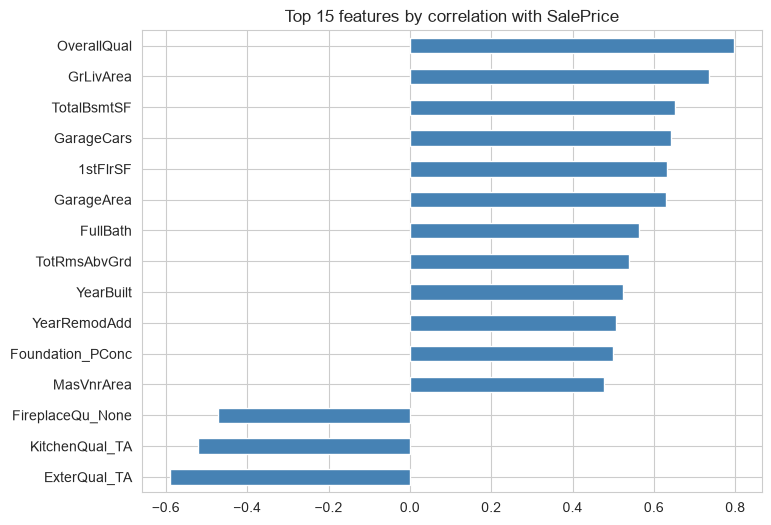

OverallQual         0.796
GrLivArea           0.735
TotalBsmtSF         0.651
GarageCars          0.641
1stFlrSF            0.632
GarageArea          0.629
ExterQual_TA       -0.590
FullBath            0.562
TotRmsAbvGrd        0.538
YearBuilt           0.524
KitchenQual_TA     -0.520
YearRemodAdd        0.508
Foundation_PConc    0.498
MasVnrArea          0.478
FireplaceQu_None   -0.472
Name: SalePrice, dtype: float64


In [14]:
# Correlation of every feature with SalePrice
corr_target = df_encoded.corr()["SalePrice"].drop("SalePrice")
top_corr = corr_target.reindex(corr_target.abs().sort_values(ascending=False).index).head(15)

plt.figure(figsize=(8, 6))
top_corr.sort_values().plot(kind="barh", color="steelblue")
plt.title("Top 15 features by correlation with SalePrice")
plt.show()
print(top_corr.round(3))

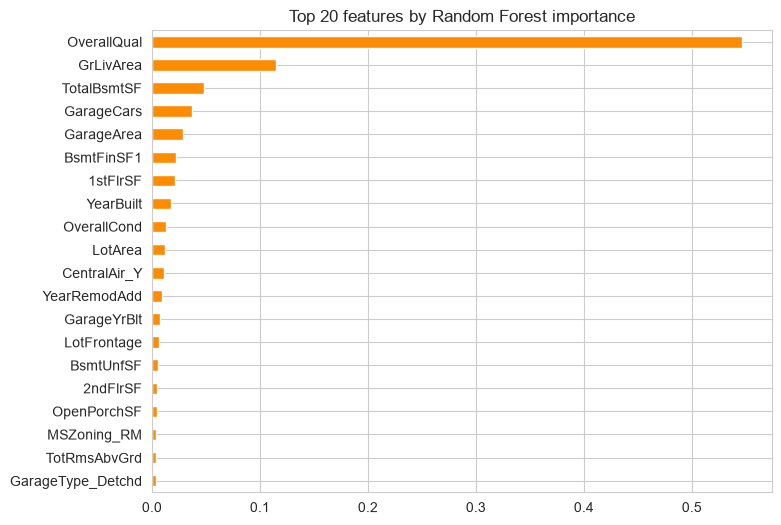

OverallQual     0.5468
GrLivArea       0.1153
TotalBsmtSF     0.0482
GarageCars      0.0371
GarageArea      0.0289
BsmtFinSF1      0.0223
1stFlrSF        0.0213
YearBuilt       0.0180
OverallCond     0.0130
LotArea         0.0120
CentralAir_Y    0.0109
YearRemodAdd    0.0092
GarageYrBlt     0.0074
LotFrontage     0.0065
BsmtUnfSF       0.0055
dtype: float64


In [15]:
# Feature importance from a Random Forest (on log price)
X_fi = df_encoded.drop(columns="SalePrice")
y_fi = np.log1p(df_encoded["SalePrice"])

rf_fi = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
rf_fi.fit(X_fi, y_fi)

importances = pd.Series(rf_fi.feature_importances_, index=X_fi.columns).sort_values(ascending=False)

plt.figure(figsize=(8, 6))
importances.head(20).sort_values().plot(kind="barh", color="darkorange")
plt.title("Top 20 features by Random Forest importance")
plt.show()
print(importances.head(15).round(4))

### Interpretation: Task 2.1 (most relevant features)

We used two different methods to find out which features matter most for the price.

**1. Correlation with `SalePrice`** (linear relationship)
- Strongest positive: `OverallQual` (**0.80**), `GrLivArea` (**0.74**), `TotalBsmtSF` (**0.65**), `GarageCars` (**0.64**), `1stFlrSF` and `GarageArea` (about 0.63).
- Strongest negative: `ExterQual_TA` (**-0.59**) and `KitchenQual_TA` (**-0.52**). These are the "typical/average" quality dummies: a house with an *average* exterior or kitchen sells for less than one with a good or excellent finish.

**2. Random Forest feature importance** (also captures non-linear effects)
- `OverallQual` is by far the most important feature (**about 55%** of the total importance), followed by `GrLivArea` (**11.5%**), `TotalBsmtSF` (4.8%) and `GarageCars` (3.7%).

**What we learn.** Both methods agree: **quality, living area, basement size and garage size** drive the price. Together, quality and size explain most of what the model needs. Many other features have very small importance (below 1%), so a lot of the 220 columns add little. We will see this again when Lasso drops most of them. Some top features are near-duplicates (`GarageCars` and `GarageArea`), so their importance is shared between them.

## Task 2.2: Create new meaningful features

In [16]:
df_fe = df_encoded.copy()

df_fe["TotalSF"] = df_fe["TotalBsmtSF"] + df_fe["1stFlrSF"] + df_fe["2ndFlrSF"]        # total living space
df_fe["HouseAge"] = df_fe["YrSold"] - df_fe["YearBuilt"]                                # age when sold
df_fe["RemodAge"] = df_fe["YrSold"] - df_fe["YearRemodAdd"]                             # years since remodel
df_fe["TotalBath"] = (df_fe["FullBath"] + 0.5 * df_fe["HalfBath"]
                      + df_fe["BsmtFullBath"] + 0.5 * df_fe["BsmtHalfBath"])            # total bathrooms
df_fe["TotalPorchSF"] = (df_fe["OpenPorchSF"] + df_fe["EnclosedPorch"] + df_fe["3SsnPorch"]
                         + df_fe["ScreenPorch"] + df_fe["WoodDeckSF"])                  # outdoor living area
df_fe["HasPool"] = (df_fe["PoolArea"] > 0).astype(int)
df_fe["HasGarage"] = (df_fe["GarageArea"] > 0).astype(int)
df_fe["Has2ndFloor"] = (df_fe["2ndFlrSF"] > 0).astype(int)
df_fe["Remodeled"] = (df_fe["YearRemodAdd"] != df_fe["YearBuilt"]).astype(int)

new_features = ["TotalSF", "HouseAge", "RemodAge", "TotalBath", "TotalPorchSF",
                "HasPool", "HasGarage", "Has2ndFloor", "Remodeled"]
print("Correlation of the new features with SalePrice:")
print(df_fe[new_features + ["SalePrice"]].corr()["SalePrice"].drop("SalePrice").sort_values(ascending=False).round(3))
print("\nFinal shape:", df_fe.shape)

Correlation of the new features with SalePrice:
TotalSF         0.833
TotalBath       0.636
TotalPorchSF    0.393
HasGarage       0.237
Has2ndFloor     0.138
HasPool         0.104
Remodeled      -0.022
RemodAge       -0.510
HouseAge       -0.524
Name: SalePrice, dtype: float64

Final shape: (1458, 221)


### Interpretation: Task 2.2 (new features)

We combined existing columns into features that describe a house more naturally.

| New feature | How it is built | Correlation with price | Meaning |
|---|---|---|---|
| `TotalSF` | basement + 1st floor + 2nd floor | **0.833** | Total living space |
| `TotalBath` | full + 0.5 x half baths (house and basement) | 0.636 | Bathroom count |
| `TotalPorchSF` | porches + deck areas | 0.393 | Outdoor living area |
| `HouseAge` | year sold - year built | -0.524 | Older houses sell for less |
| `RemodAge` | year sold - year remodeled | -0.510 | Recently renovated houses sell for more |
| `HasGarage`, `Has2ndFloor`, `HasPool` | yes/no flags | 0.24 / 0.14 / 0.10 | Weak but positive |
| `Remodeled` | remodeled or not | -0.022 | Almost no effect on its own |

**Key result:** `TotalSF` has a correlation of **0.833**, higher than any original feature (the best one was `OverallQual` at 0.796). Adding up the separate areas gives a single, stronger predictor. `HouseAge` and `RemodAge` are negative because the older a house is, the lower its price. `Remodeled` is close to zero, so by itself it is not useful (the *age* of the renovation matters more than whether one happened).

The dataset now has **221 columns** (220 features + `SalePrice`).

# Task 3: Model Training & Evaluation

## Task 3.1: Split the data into training and test sets (and scale the features)

In [17]:
X = df_fe.drop(columns="SalePrice")
y = np.log1p(df_fe["SalePrice"])          # we predict log(price), then convert back with expm1

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape, " Test:", X_test.shape)

# Scaling (Task 1.5): fit on train only, then apply to test
scaler = StandardScaler()
X_train_s = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test_s = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)

Train: (1166, 220)  Test: (292, 220)


### Interpretation: Task 3.1 (train/test split and scaling)

- **80/20 split:** **1,166 houses** are used to train the model and **292 houses** are held back as a test set. The model never sees the test houses during training, so the test score shows how it performs on new, unseen houses. `random_state=42` makes the split the same every time so the results can be reproduced.
- **Target:** we predict `log(1 + SalePrice)`, as explained in the EDA part.
- **Scaling (Task 1.5):** `StandardScaler` converts every feature to mean 0 and standard deviation 1, so a feature measured in thousands (square feet) does not dominate one measured from 1 to 10. This matters for **Ridge and Lasso**, whose penalty depends on the size of the coefficients, and helps Linear Regression numerically. Tree models do not need it, but it does no harm.
- **No data leakage:** the scaler is **fit on the training data only**, and then applied to the test data. If we had fit it on all the data, information about the test set would leak into training and make the score look better than it really is.

## Task 3.2: Train at least three different regression models

In [18]:
def evaluate(name, model, Xtr, Xte):
    """Fit the model, predict, and return MAE, RMSE and R2 (in dollars), plus RMSE on log price."""
    model.fit(Xtr, y_train)
    pred_log = model.predict(Xte)
    pred = np.expm1(pred_log)
    actual = np.expm1(y_test)
    return {
        "Model": name,
        "MAE ($)": mean_absolute_error(actual, pred),
        "RMSE ($)": np.sqrt(mean_squared_error(actual, pred)),
        "RMSE (log)": np.sqrt(mean_squared_error(y_test, pred_log)),
        "R2": r2_score(actual, pred),
    }

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}

results = [evaluate(name, m, X_train_s, X_test_s) for name, m in models.items()]
results_df = pd.DataFrame(results).set_index("Model")
results_df.round(4)

,MAE ($),RMSE ($),RMSE (log),R2
Model,,,,
Linear Regression,14767.4522,21138.5455,0.1308,0.9191
Random Forest,16655.7179,23848.6290,0.1467,0.8970
Gradient Boosting,14847.8557,20542.5540,0.1269,0.9236


### Interpretation: Task 3.2 (training three models)

We trained three different types of regression model on the same data:
- **Linear Regression:** fits one straight-line formula (a weighted sum of all features). Simple and fast.
- **Random Forest:** averages 300 decision trees, each trained on a random part of the data. Can capture non-linear effects.
- **Gradient Boosting:** builds trees one after another, where each new tree corrects the mistakes of the previous ones.

**How to read the metrics** (all converted back to dollars)
- **MAE:** the average size of the error. An MAE of $14,767 means the predictions are off by about $14.8k on average.
- **RMSE:** like MAE but it punishes big mistakes more, so it is always higher. A large gap between RMSE and MAE means some predictions are far off.
- **R²:** the share of the price variation the model explains. 0.92 means 92%.
- **RMSE (log):** the error on the log scale (a relative error). We use it to pick the best model.

| Model | MAE ($) | RMSE ($) | R² |
|---|---|---|---|
| Linear Regression | 14,767 | 21,139 | 0.9191 |
| Random Forest | 16,656 | 23,849 | 0.8970 |
| Gradient Boosting | 14,848 | 20,543 | 0.9236 |

All three models explain roughly 90% to 92% of the variation in prices, so the data preparation and feature engineering did most of the work.

## Task 3.3: Compare the models using MAE, RMSE and R²

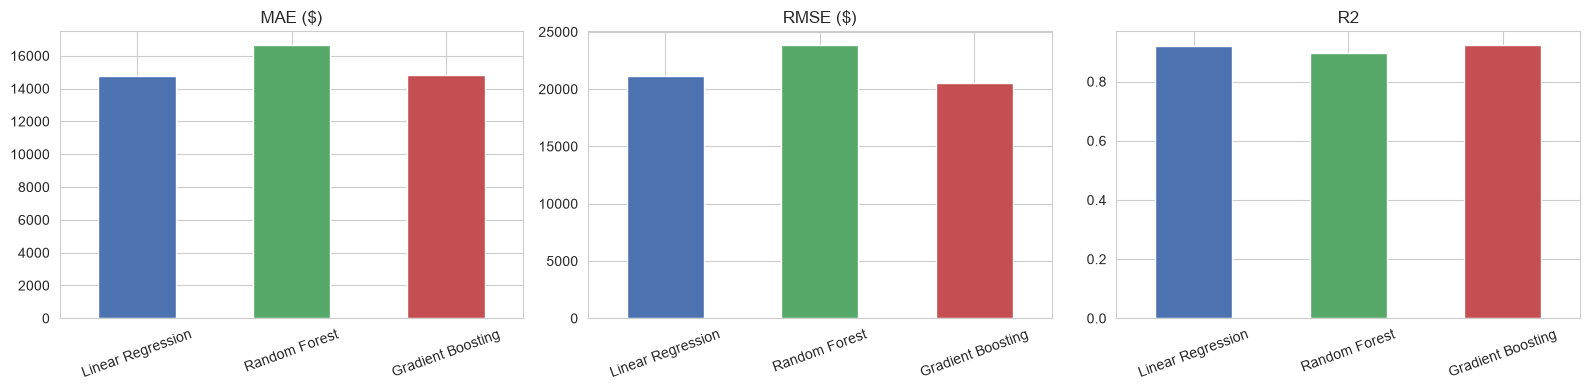

Best model so far (lowest RMSE on log price): Gradient Boosting


In [19]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, metric in zip(axes, ["MAE ($)", "RMSE ($)", "R2"]):
    results_df[metric].plot(kind="bar", ax=ax, color=["#4c72b0", "#55a868", "#c44e52"])
    ax.set_title(metric)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

best_name = results_df["RMSE (log)"].idxmin()
print("Best model so far (lowest RMSE on log price):", best_name)

### Interpretation and conclusion: Task 3.3 (comparing the models)

The bar charts compare the three models on MAE, RMSE and R² (lower is better for MAE and RMSE, higher is better for R²).

- **Gradient Boosting performed best overall.** It has the lowest RMSE ($20,543), the lowest log-RMSE (0.1269) and the highest R² (0.9236). That is why it was selected as the model to tune.
- **Linear Regression was surprisingly close.** Its MAE ($14,767) is actually slightly lower than untuned Gradient Boosting ($14,848). Once the target is log-transformed and good features (such as `TotalSF`) are created, the relationship between the features and price is mostly linear, so a simple model does well.
- **Random Forest was the weakest** (MAE $16,656, R² 0.897). One possible reason is that after one-hot encoding there are many sparse 0/1 columns, which makes it harder for a forest of independent trees to find the important splits. It also was not tuned.
- **Why Gradient Boosting wins:** it improves step by step by fixing earlier errors and can capture non-linear effects and interactions between features (for example, a big house in an expensive neighborhood), which a single straight-line formula cannot.

**Conclusion:** Gradient Boosting is the best model, although the gap with Linear Regression is small. We continue to Task 4 to tune it.

# Task 4: Hyperparameter Tuning

## Task 4.1: Optimize the best-performing model with Grid Search

In [20]:
# Grid Search with 5-fold cross-validation on Gradient Boosting
# (this can take a few minutes; n_jobs=-1 uses all CPU cores)
param_grid = {
    "n_estimators": [200, 400],
    "learning_rate": [0.03, 0.05, 0.1],
    "max_depth": [2, 3, 4],
}

grid = GridSearchCV(
    GradientBoostingRegressor(random_state=42),
    param_grid,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    verbose=1,
)
grid.fit(X_train_s, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV RMSE (log):", round(-grid.best_score_, 4))

Fitting 5 folds for each of 18 candidates, totalling 90 fits
Best parameters: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 400}
Best CV RMSE (log): 0.1221


### Interpretation: Task 4.1 (Grid Search)

**What Grid Search does.** It tries every combination of the settings (hyperparameters) we give it and scores each one with 5-fold cross-validation (the training data is split into 5 parts; the model trains on 4 and is checked on the 5th, and this is repeated 5 times). We tested 2 values of `n_estimators` x 3 of `learning_rate` x 3 of `max_depth` = **18 combinations x 5 folds = 90 fits**.

**Best settings found:** `n_estimators = 400`, `learning_rate = 0.05`, `max_depth = 3`, with a cross-validated RMSE (log) of **0.1221**.

**What this means**
- A **small learning rate (0.05) with many trees (400)** means the model learns slowly and carefully, which usually generalizes better than learning fast with fewer trees.
- **Shallow trees (depth 3)** keep each tree simple, which prevents overfitting. The deeper trees (depth 4) did not help.
- The best `n_estimators` (400) is the **largest value in our grid**, so trying even more trees (e.g. 600) could improve it slightly. The learning rate and depth are in the middle of their ranges, so they look well chosen.
- The CV score (0.1221) is measured on the training folds, so it cannot be compared directly with the test score. The real check is in Task 4.2.

## Task 4.2: Evaluate the tuned model and compare it with the untuned one

In [21]:
best_gb = grid.best_estimator_
tuned_result = evaluate("Gradient Boosting (tuned)", best_gb, X_train_s, X_test_s)

comparison = pd.concat([results_df, pd.DataFrame([tuned_result]).set_index("Model")])
comparison.round(4)

,MAE ($),RMSE ($),RMSE (log),R2
Model,,,,
Linear Regression,14767.4522,21138.5455,0.1308,0.9191
Random Forest,16655.7179,23848.6290,0.1467,0.8970
Gradient Boosting,14847.8557,20542.5540,0.1269,0.9236
Gradient Boosting (tuned),14261.3006,20462.5616,0.1262,0.9242


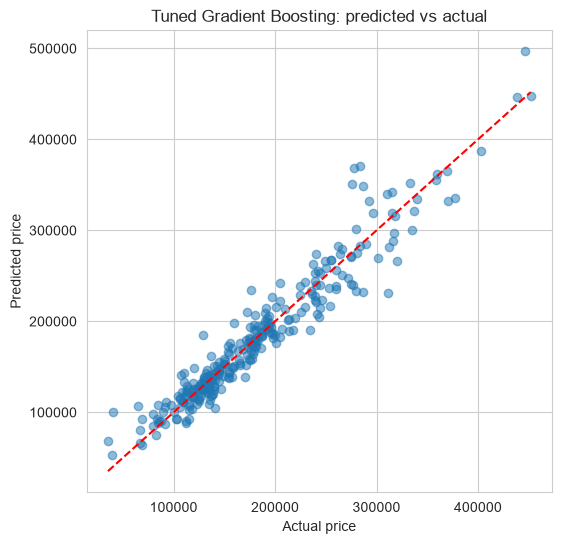

In [22]:
# Predicted vs actual prices for the tuned model
pred_tuned = np.expm1(best_gb.predict(X_test_s))
actual = np.expm1(y_test)

plt.figure(figsize=(6, 6))
plt.scatter(actual, pred_tuned, alpha=0.5)
lims = [actual.min(), actual.max()]
plt.plot(lims, lims, "r--")
plt.xlabel("Actual price")
plt.ylabel("Predicted price")
plt.title("Tuned Gradient Boosting: predicted vs actual")
plt.show()

### Interpretation: Task 4.2 (tuned vs untuned model)

| Metric | Before tuning | After tuning | Change |
|---|---|---|---|
| MAE ($) | 14,848 | **14,261** | -587 |
| RMSE ($) | 20,543 | **20,463** | -80 |
| R² | 0.9236 | **0.9242** | +0.0006 |

**Result:** tuning improved every metric, but only by a small amount. The average error dropped by about **$587 (about 4%)**. This tells us the default Gradient Boosting was already close to its best, and the real gains came earlier from data cleaning, the log transform and feature engineering. The tuned model explains **92.4%** of the variation in house prices on unseen data.

**Predicted vs actual plot.** Each dot is one test house; the red dashed line is a perfect prediction. The dots stay close to the line, so the predictions are accurate. The spread is wider for **expensive houses (above about $250k)**, where the model both over- and under-predicts. There are fewer expensive examples to learn from, and luxury homes depend on details that are not in the data. For cheap and medium houses (which are the majority) the predictions are tight.

# Bonus Challenge

## Bonus 1: Train Ridge and Lasso and compare them with Linear Regression

In [23]:
# RidgeCV / LassoCV choose the best regularization strength (alpha) automatically
ridge = RidgeCV(alphas=np.logspace(-1, 3, 30))
lasso = LassoCV(alphas=np.logspace(-4, -1, 30), cv=5, max_iter=50000)

bonus_results = [
    evaluate("Ridge", ridge, X_train_s, X_test_s),
    evaluate("Lasso", lasso, X_train_s, X_test_s),
]
bonus_df = pd.DataFrame(bonus_results).set_index("Model")

print("Best Ridge alpha:", round(ridge.alpha_, 3))
print("Best Lasso alpha:", round(lasso.alpha_, 5))
print("Lasso kept", int((lasso.coef_ != 0).sum()), "of", X_train_s.shape[1], "features")

all_results = pd.concat([results_df, bonus_df, pd.DataFrame([tuned_result]).set_index("Model")])
all_results.sort_values("RMSE (log)").round(4)

Best Ridge alpha: 148.735
Best Lasso alpha: 0.00356
Lasso kept 81 of 220 features


,MAE ($),RMSE ($),RMSE (log),R2
Model,,,,
Lasso,14476.7957,20272.2607,0.1241,0.9256
Gradient Boosting (tuned),14261.3006,20462.5616,0.1262,0.9242
Gradient Boosting,14847.8557,20542.5540,0.1269,0.9236
Ridge,14932.8357,21085.9293,0.1307,0.9195
Linear Regression,14767.4522,21138.5455,0.1308,0.9191
Random Forest,16655.7179,23848.6290,0.1467,0.8970


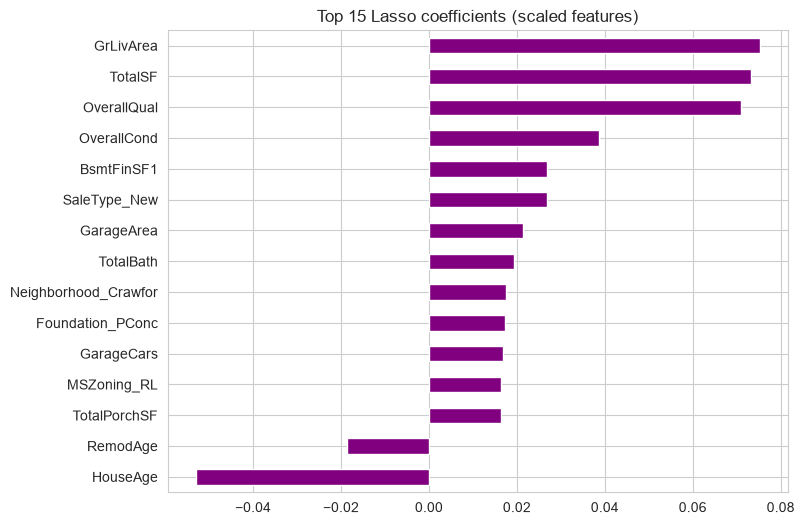

In [24]:
# Which features did Lasso find most important?
lasso_coefs = pd.Series(lasso.coef_, index=X.columns)
top_lasso = lasso_coefs.reindex(lasso_coefs.abs().sort_values(ascending=False).index).head(15)

plt.figure(figsize=(8, 6))
top_lasso.sort_values().plot(kind="barh", color="purple")
plt.title("Top 15 Lasso coefficients (scaled features)")
plt.show()

### Interpretation: Bonus 1 (Ridge and Lasso vs Linear Regression)

**The idea.** Linear Regression uses all 220 features with no restriction. Many of them are correlated with each other (for example `TotalSF` is built from other columns, and `GarageCars` is close to `GarageArea`), so it can give large, unstable coefficients and **overfit**. Ridge and Lasso fix this by adding a **penalty** on large coefficients:
- **Ridge** shrinks all coefficients toward zero but keeps every feature.
- **Lasso** can shrink coefficients **all the way to zero**, which removes features, so it also does automatic feature selection.

`RidgeCV` and `LassoCV` choose the penalty strength (alpha) automatically with cross-validation: **Ridge alpha = 148.7**, **Lasso alpha = 0.00356**.

| Model | MAE ($) | RMSE ($) | RMSE (log) | R² |
|---|---|---|---|---|
| **Lasso** | 14,477 | **20,272** | **0.1241** | **0.9256** |
| Gradient Boosting (tuned) | **14,261** | 20,463 | 0.1262 | 0.9242 |
| Gradient Boosting | 14,848 | 20,543 | 0.1269 | 0.9236 |
| Ridge | 14,933 | 21,086 | 0.1307 | 0.9195 |
| Linear Regression | 14,767 | 21,139 | 0.1308 | 0.9191 |
| Random Forest | 16,656 | 23,849 | 0.1467 | 0.8970 |

**What we learn**
- **Ridge is only slightly better than Linear Regression** (R² 0.9195 vs 0.9191). Shrinking the coefficients helps a little, but it keeps all the redundant features.
- **Lasso is clearly better than Linear Regression** (RMSE $20,272 vs $21,139, R² 0.9256 vs 0.9191), and it did so while using **only 81 of the 220 features**. So more than half of the features were noise or duplicates, and removing them improved the model on unseen data.
- **Lasso even matches or beats the tuned Gradient Boosting** on RMSE and R², although the tuned Gradient Boosting has a slightly lower MAE. The differences between the top three are small (about 1% in RMSE), so they perform almost equally well on this split.
- A simple, regularized linear model is therefore a very strong choice for this dataset, and it is easy to explain.

**Lasso coefficients plot.** Features are on the same scale, so the bar sizes can be compared. The biggest positive effects are `GrLivArea`, `TotalSF` and `OverallQual` (size and quality, the same features found important in Task 2.1), followed by `OverallCond`. The biggest negative effects are `HouseAge` and `RemodAge`: older houses sell for less. `SaleType_New` is positive, meaning newly built houses sell at a premium. This confirms the results of the feature analysis.

## Bonus 2: Deploy the model as a web app with Streamlit

The web form only asks for a few key features, so we train a smaller version of the model on those 8 features and save it.

In [25]:
import joblib

app_features = ["OverallQual", "GrLivArea", "TotalBsmtSF", "GarageCars",
                "FullBath", "YearBuilt", "LotArea", "Fireplaces"]

Xa = df_fe[app_features]
Xa_train, Xa_test, ya_train, ya_test = train_test_split(Xa, y, test_size=0.2, random_state=42)

# Same tuned hyperparameters as before (trees do not need scaling)
app_model = GradientBoostingRegressor(**grid.best_params_, random_state=42)
app_model.fit(Xa_train, ya_train)

pred_app = np.expm1(app_model.predict(Xa_test))
print("Small model R2 on test set:", round(r2_score(np.expm1(ya_test), pred_app), 4))
print("Small model MAE ($):", round(mean_absolute_error(np.expm1(ya_test), pred_app)))

# Refit on all the data, then save for the app
app_model.fit(Xa, y)
joblib.dump({"model": app_model, "features": app_features}, "house_model.pkl")
print("Saved house_model.pkl")

Small model R2 on test set: 0.8921
Small model MAE ($): 17231
Saved house_model.pkl


In [26]:
%%writefile app.py
import streamlit as st
import joblib
import numpy as np
import pandas as pd

artifact = joblib.load("house_model.pkl")
model = artifact["model"]
features = artifact["features"]

st.set_page_config(page_title="House Price Predictor")
st.title("House Price Predictor")
st.write("Enter the house features and get an estimated sale price.")

col1, col2 = st.columns(2)
with col1:
    overall_qual = st.slider("Overall quality (1-10)", 1, 10, 5)
    gr_liv_area = st.number_input("Above-ground living area (sq ft)", 300, 6000, 1500, step=50)
    total_bsmt = st.number_input("Total basement area (sq ft)", 0, 4000, 800, step=50)
    garage_cars = st.slider("Garage capacity (cars)", 0, 4, 2)
with col2:
    full_bath = st.slider("Full bathrooms", 0, 4, 2)
    year_built = st.number_input("Year built", 1870, 2025, 1990, step=1)
    lot_area = st.number_input("Lot area (sq ft)", 1000, 50000, 9000, step=500)
    fireplaces = st.slider("Fireplaces", 0, 3, 1)

if st.button("Predict price"):
    row = pd.DataFrame([{
        "OverallQual": overall_qual,
        "GrLivArea": gr_liv_area,
        "TotalBsmtSF": total_bsmt,
        "GarageCars": garage_cars,
        "FullBath": full_bath,
        "YearBuilt": year_built,
        "LotArea": lot_area,
        "Fireplaces": fireplaces,
    }])[features]
    price = np.expm1(model.predict(row)[0])
    st.success(f"Estimated price: ${price:,.0f}")

Writing app.py


**Run the app:** open a terminal (or Anaconda Prompt) in the same folder as this notebook and run:

```
pip install streamlit
streamlit run app.py
```

A browser tab opens automatically with the app.

### Interpretation: Bonus 2 (deploying the model as a web app)

**Why a smaller model.** The final model uses 220 features, but a person using a website cannot be expected to enter 220 values. So we trained a **smaller model that uses only 8 inputs a user would know**: overall quality, living area, basement area, garage size, bathrooms, year built, lot area and fireplaces. These are the strongest features found in Task 2.1.

**Accuracy trade-off.** On the test set the small model reaches **R² = 0.892** and **MAE = $17,231**, compared with R² = 0.924 and MAE = $14,261 for the full model. It is a little less accurate, but it is much easier to use. Fewer inputs means the model cannot see details like neighborhood or exterior quality, so more of the error is unexplained.

**Steps to deploy**
1. Retrain the model on the 8 features with the tuned settings, check its score, then **refit on all the data** (more data gives a slightly better final model) and save it with `joblib` as `house_model.pkl`.
2. Write the web app (`app.py`). It loads the saved model, shows a form, converts the entered values into a table row, predicts the log price and converts it back to dollars with `expm1`.
3. Run it with `streamlit run app.py` and the app opens in the browser.

**Flask version.** The project folder `house-price-app` contains a second, production-ready version of the same idea built with **Flask**. It also asks for the neighborhood and the kitchen quality, validates the inputs, and includes a JSON API, tests, a Dockerfile and a README for deployment.

**Limitations.** The model only knows houses sold in **Ames, Iowa between 2006 and 2010**, and its estimate is not an appraisal. It will be less reliable for unusual inputs (e.g. a very large or very new house) than for typical ones.

In [27]:
summary = pd.DataFrame([evaluate("My final model (Gradient Boosting tuned)", best_gb, X_train_s, X_test_s)])
summary["Best parameters"] = str(grid.best_params_)
summary["Split"] = "test_size=0.2, random_state=42"
summary["Target"] = "log1p(SalePrice); MAE/RMSE/R2 reported in dollars"
summary.to_csv("my_results.csv", index=False)
summary.T

,0
Model,My final model (Gradient Boosting tuned)
MAE ($),14261.300598
RMSE ($),20462.5616
RMSE (log),0.126186
R2,0.924197
Best parameters,"{'learning_rate': 0.05, 'max_depth': 3, 'n_est..."
Split,"test_size=0.2, random_state=42"
Target,log1p(SalePrice); MAE/RMSE/R2 reported in dollars


In [28]:
before = comparison.loc["Gradient Boosting"]
after = comparison.loc["Gradient Boosting (tuned)"]

change = pd.DataFrame({
    "Before tuning": before,
    "After tuning": after,
    "Change": after - before,
})
change.round(4)

,Before tuning,After tuning,Change
MAE ($),14847.8557,14261.3006,-586.5551
RMSE ($),20542.5540,20462.5616,-79.9924
RMSE (log),0.1269,0.1262,-0.0007
R2,0.9236,0.9242,0.0006


### Overall conclusion

- **Data:** the dataset was cleaned (missing values handled, 2 outliers removed), categorical variables were one-hot encoded, and 9 new features were created. `TotalSF` became the best single predictor (correlation 0.83).
- **Most important features:** overall quality, living area, basement and garage size, house age and neighborhood.
- **Models:** Gradient Boosting was the best of the three required models. After Grid Search its test results were **MAE $14,261, RMSE $20,463 and R² 0.924**.
- **Bonus:** Lasso (R² 0.9256) and Ridge (0.9195) were compared with Linear Regression (0.9191). Regularization helped, and Lasso reached the same accuracy as the tuned Gradient Boosting with only 81 of 220 features.
- **Deployment:** a smaller 8-feature model was saved and served in a web application, so users can enter house features and receive a price estimate.
- **Next steps:** more tuning (more trees, other algorithms such as XGBoost), combining Lasso and Gradient Boosting (ensembling), and using more recent data.